# KNN multi-classes — Prédiction de la classe du passager (Titanic)

**Question 3 :** appliquer la même technique (choix de k + KNN *from scratch*) sur un dataset
ayant **plus de deux classes**.

**Dataset :** `../data/Titanic-Dataset.csv` — 884 passagers.

### Choix de la variable cible
La cible « classique » du Titanic, `Survived`, n'a que **2 classes**. Pour répondre à la question,
on prédit **`Pclass`**, la classe du billet, qui en a **3** :

| Pclass | Signification |
|---|---|
| 1 | 1ʳᵉ classe |
| 2 | 2ᵉ classe |
| 3 | 3ᵉ classe |

**Question posée au modèle :** à partir du prix du billet, de l'âge, du sexe, de la famille à bord,
de la présence d'une cabine et de la survie, peut-on retrouver la classe d'un passager ?

### Ce qui change par rapport au cas binaire (cancer)
1. **Vote majoritaire à 3 classes** : un k impair **ne garantit plus** l'absence d'égalité
   (ex. k = 5 → 2 voix / 2 voix / 1 voix). Il faut une règle de départage explicite.
2. **Données réelles « sales »** : valeurs manquantes (`Age`), variables texte (`Sex`, `Cabin`),
   variable très asymétrique (`Fare`) → un vrai pré-traitement est nécessaire.
3. **Classes déséquilibrées** (3ᵉ classe majoritaire) → on complète l'accuracy par des métriques
   **par classe** et des moyennes **macro**.
4. **Groupes de passagers** : les membres d'une même famille partagent le même billet
   (même prix, même classe). On en tient compte dans la séparation des données (voir §2).

## 0. Importation des bibliothèques

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Utilisés UNIQUEMENT en Partie 1 (choix de k) et pour valider le modèle from scratch
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

CLASSES = [1, 2, 3]
NOMS = {1: "1re classe", 2: "2e classe", 3: "3e classe"}
COULEURS = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}   # ordre fixe : bleu, orange, vert d'eau

## 1. Chargement et exploration des données

In [2]:
df = pd.read_csv("../data/Titanic-Dataset.csv")
print("Dimensions :", df.shape)
df.head()

Dimensions : (884, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print("Valeurs manquantes :")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nRépartition de la cible Pclass :")
print(df["Pclass"].value_counts().sort_index().rename(index=NOMS))

Valeurs manquantes :
Age         174
Cabin       680
Embarked      2
dtype: int64

Répartition de la cible Pclass :
Pclass
1re classe    216
2e classe     182
3e classe     486
Name: count, dtype: int64


**Observations :**
- `Age` : 174 valeurs manquantes → à imputer.
- `Cabin` : 680 valeurs manquantes (77 %) → inutilisable telle quelle, mais le simple fait
  **d'avoir une cabine renseignée** est très informatif (surtout en 1ʳᵉ classe).
- `Embarked` : 2 valeurs manquantes.
- La cible est **déséquilibrée** : la 3ᵉ classe représente ≈ 55 % des passagers.

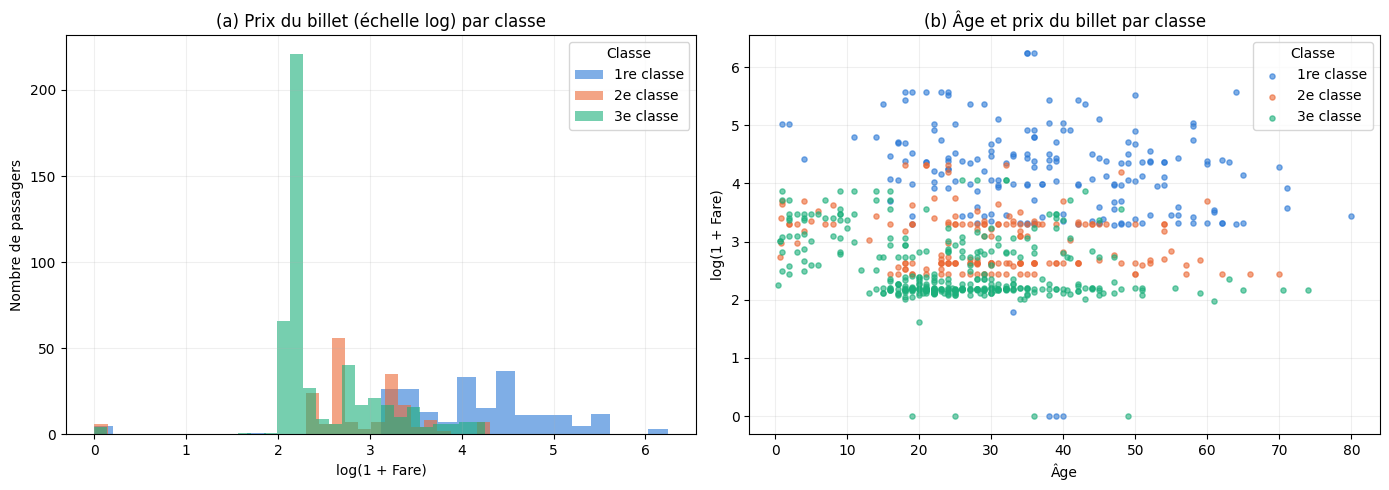

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for c in CLASSES:
    ax.hist(np.log1p(df.loc[df["Pclass"] == c, "Fare"]), bins=30, alpha=0.6,
            color=COULEURS[c], label=NOMS[c])
ax.set_xlabel("log(1 + Fare)")
ax.set_ylabel("Nombre de passagers")
ax.set_title("(a) Prix du billet (échelle log) par classe")
ax.legend(title="Classe")
ax.grid(alpha=0.2)

ax = axes[1]
for c in CLASSES:
    sous = df[df["Pclass"] == c]
    ax.scatter(sous["Age"], np.log1p(sous["Fare"]), s=14, alpha=0.6,
               color=COULEURS[c], label=NOMS[c])
ax.set_xlabel("Âge")
ax.set_ylabel("log(1 + Fare)")
ax.set_title("(b) Âge et prix du billet par classe")
ax.legend(title="Classe")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**Interprétation :**
- (a) Le **prix du billet** est la variable la plus discriminante : la 1ʳᵉ classe est nettement
  plus chère. Les 2ᵉ et 3ᵉ classes se **chevauchent** fortement → ce sont elles que le modèle
  confondra le plus.
- (b) Les passagers de 1ʳᵉ classe sont en moyenne **plus âgés**.
- `Fare` est très asymétrique (quelques billets à plus de 500) : on utilise **log(1 + Fare)**,
  sinon ces valeurs extrêmes écraseraient toutes les distances.

## 2. Préparation des données

### 2.1 Variables retenues
| Variable | Transformation | Justification |
|---|---|---|
| `Fare` | `LogFare = log(1 + Fare)` | réduit l'asymétrie |
| `Age` | imputation par la **médiane du jeu d'entraînement** | 174 valeurs manquantes |
| `SibSp`, `Parch` | aucune | taille de la famille à bord |
| `Sex` | 1 = femme, 0 = homme | variable texte → numérique |
| `Cabin` | `HasCabin` = 1 si renseignée, 0 sinon | 77 % manquant, mais la présence est informative |
| `Survived` | aucune | le taux de survie dépend fortement de la classe |

Variables **écartées** : `PassengerId`, `Name`, `Ticket` (identifiants, pas de sens en distance)
et `Embarked`. Le port d'embarquement codé en one-hot ajoute 3 dimensions pour un gain
négligeable, et fait basculer le choix vers k = 1, le modèle le plus sensible au bruit
(vérifié dans la cellule de comparaison plus bas).

Les transformations ci-dessous sont faites **ligne par ligne** (aucune statistique calculée sur
l'ensemble des données), donc **sans fuite d'information**. L'imputation de l'âge et la
standardisation, elles, utilisent des statistiques : elles sont apprises **sur l'entraînement uniquement**.

In [5]:
data = pd.DataFrame({
    "LogFare": np.log1p(df["Fare"]),
    "Age": df["Age"],                                  # NaN conservés : imputés plus tard
    "SibSp": df["SibSp"],
    "Parch": df["Parch"],
    "Sex": (df["Sex"] == "female").astype(int),
    "HasCabin": df["Cabin"].notna().astype(int),
    "Survived": df["Survived"],
})
VARIABLES = list(data.columns)

X = data.values
y = df["Pclass"].values
groupes = df["Ticket"].values      # identifiant du groupe de voyage
data.head()

,LogFare,Age,SibSp,Parch,Sex,HasCabin,Survived
0,2.110213,22.0,1,0,0,0,0
1,4.280593,38.0,1,0,1,1,1
2,2.188856,26.0,0,0,1,0,1
3,3.990834,35.0,1,0,1,1,1
4,2.202765,35.0,0,0,0,0,0


### 2.2 Séparation entraînement / test **par groupe de billet**
341 passagers partagent leur billet avec d'autres (familles, amis). Ils ont **le même prix
et la même classe**. Avec une séparation aléatoire classique, un passager du test aurait souvent
son compagnon de voyage dans l'entraînement : KNN le trouverait comme voisin le plus proche et
« recopierait » sa classe. La performance serait **artificiellement gonflée** et le choix de k biaisé
vers k = 1.

Solution : `GroupShuffleSplit` — **tous les passagers d'un même billet** vont soit dans
l'entraînement, soit dans le test (70 % / 30 %).

In [6]:
separateur = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=RANDOM_STATE)
idx_train, idx_test = next(separateur.split(X, y, groupes))

X_train, X_test = X[idx_train], X[idx_test]
y_train, y_test = y[idx_train], y[idx_test]
groupes_train = groupes[idx_train]

print("Entraînement :", X_train.shape, "| Test :", X_test.shape)
print("Billets communs aux deux ensembles :",
      len(set(groupes_train) & set(groupes[idx_test])))
print("\nRépartition des classes :")
print(pd.DataFrame({
    "train": pd.Series(y_train).value_counts(normalize=True).sort_index(),
    "test": pd.Series(y_test).value_counts(normalize=True).sort_index(),
}).rename(index=NOMS).round(3))

Entraînement : (616, 7) | Test : (268, 7)
Billets communs aux deux ensembles : 0

Répartition des classes :
            train   test
1re classe  0.239  0.257
2e classe   0.209  0.198
3e classe   0.552  0.545


---
# Partie 1 — Détermination du nombre optimal de voisins k

Même méthode que pour le dataset cancer : **validation croisée à 10 plis** sur le jeu
d'entraînement, pour les k impairs de 1 à 51. On utilise `StratifiedGroupKFold` :
- **stratifié** : chaque pli garde à peu près les mêmes proportions de classes ;
- **groupé** : un même billet n'est jamais à la fois dans la partie d'apprentissage et de validation.

Le pipeline `imputation (médiane) → standardisation → KNN` est réajusté sur chaque pli :
aucune information de validation ne fuit.

*Remarque :* on garde les k impairs par cohérence avec le cas binaire, mais avec 3 classes
cela ne suffit plus à éviter les égalités (traité en Partie 2).

In [7]:
def creer_pipeline(k):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         KNeighborsClassifier(n_neighbors=k))

valeurs_k = list(range(1, 52, 2))
cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

cv_moyenne, cv_ecart_type, acc_train = [], [], []
for k in valeurs_k:
    scores = cross_val_score(creer_pipeline(k), X_train, y_train, groups=groupes_train,
                             cv=cv, scoring="accuracy")
    cv_moyenne.append(scores.mean())
    cv_ecart_type.append(scores.std())
    acc_train.append(creer_pipeline(k).fit(X_train, y_train).score(X_train, y_train))

resultats_k = pd.DataFrame({
    "k": valeurs_k,
    "accuracy_train": acc_train,
    "accuracy_cv": cv_moyenne,
    "ecart_type_cv": cv_ecart_type,
    "taux_erreur_cv": 1 - np.array(cv_moyenne),
})
resultats_k.round(4)

,k,accuracy_train,accuracy_cv,ecart_type_cv,taux_erreur_cv
0,1,0.9968,0.8367,0.0600,0.1633
1,3,0.9318,0.8280,0.0471,0.1720
2,5,0.8929,0.8388,0.0383,0.1612
3,7,0.8815,0.8313,0.0440,0.1687
4,9,0.8718,0.8160,0.0415,0.1840
5,11,0.8620,0.8038,0.0420,0.1962
6,13,0.8523,0.7979,0.0420,0.2021
7,15,0.8409,0.7958,0.0420,0.2042
8,17,0.8279,0.7921,0.0405,0.2079
9,19,0.8166,0.7826,0.0384,0.2174


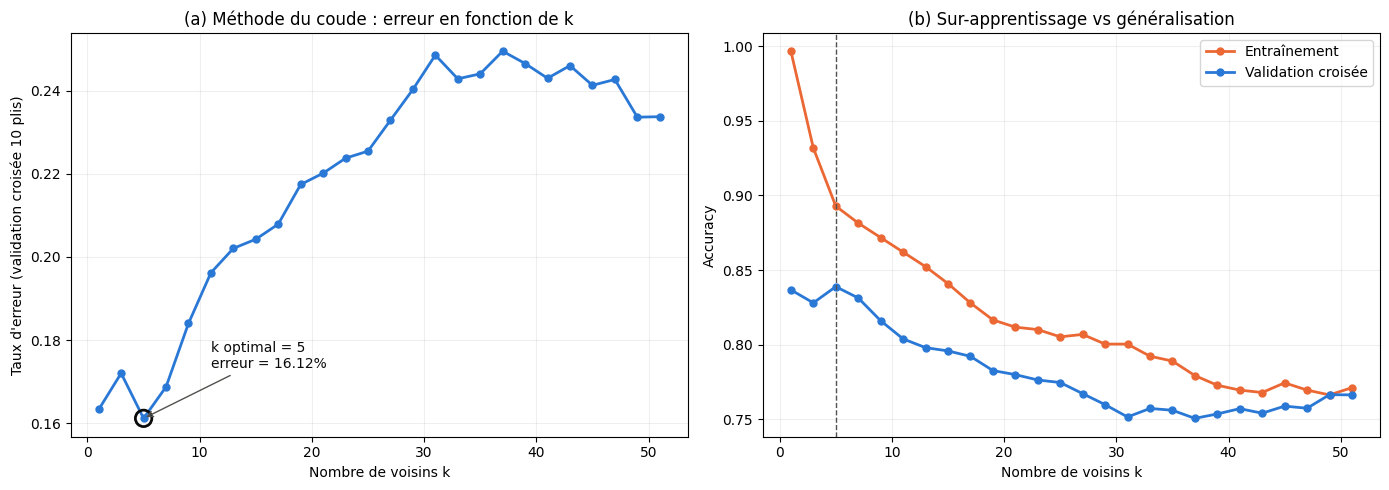

k optimal retenu : 5  (accuracy CV = 0.8388)


In [8]:
k_optimal = int(resultats_k.loc[resultats_k["accuracy_cv"].idxmax(), "k"])
erreur_min = resultats_k["taux_erreur_cv"].min()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(resultats_k["k"], resultats_k["taux_erreur_cv"], color="#2a78d6", lw=2,
        marker="o", markersize=5)
ax.scatter([k_optimal], [erreur_min], s=140, facecolors="none",
           edgecolors="#0b0b0b", linewidths=2, zorder=3)
ax.annotate(f"k optimal = {k_optimal}\nerreur = {erreur_min:.2%}",
            xy=(k_optimal, erreur_min), xytext=(k_optimal + 6, erreur_min + 0.012),
            arrowprops=dict(arrowstyle="->", color="#52514e"), color="#0b0b0b")
ax.set_xlabel("Nombre de voisins k")
ax.set_ylabel("Taux d'erreur (validation croisée 10 plis)")
ax.set_title("(a) Méthode du coude : erreur en fonction de k")
ax.grid(alpha=0.2)

ax = axes[1]
ax.plot(resultats_k["k"], resultats_k["accuracy_train"], color="#eb6834", lw=2,
        marker="o", markersize=5, label="Entraînement")
ax.plot(resultats_k["k"], resultats_k["accuracy_cv"], color="#2a78d6", lw=2,
        marker="o", markersize=5, label="Validation croisée")
ax.axvline(k_optimal, color="#52514e", ls="--", lw=1)
ax.set_xlabel("Nombre de voisins k")
ax.set_ylabel("Accuracy")
ax.set_title("(b) Sur-apprentissage vs généralisation")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print(f"k optimal retenu : {k_optimal}  (accuracy CV = {resultats_k['accuracy_cv'].max():.4f})")

### Vérification : pourquoi avoir écarté `Embarked` et séparé par billet ?
On compare la meilleure accuracy de validation croisée (et le k associé) pour différents choix.

In [9]:
emb = pd.get_dummies(df["Embarked"].fillna("S"), prefix="Emb", dtype=int).values
X_avec_emb = np.hstack([X, emb])


def meilleur_k(X_, cv_, groupes_=None):
    res = []
    for k in valeurs_k:
        sc = cross_val_score(creer_pipeline(k), X_, y_train, groups=groupes_, cv=cv_)
        res.append((k, sc.mean(), sc.std()))
    return max(res, key=lambda t: t[1])


from sklearn.model_selection import StratifiedKFold
cv_naif = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

comparaison_choix = pd.DataFrame(
    [("7 variables, CV groupée par billet (retenu)", *meilleur_k(X_train, cv, groupes_train)),
     ("+ Embarked, CV groupée par billet", *meilleur_k(X_avec_emb[idx_train], cv, groupes_train)),
     ("7 variables, CV NON groupée (naïve)", *meilleur_k(X_train, cv_naif))],
    columns=["configuration", "meilleur k", "accuracy CV", "écart-type entre plis"]).round(4)
comparaison_choix

,configuration,meilleur k,accuracy CV,écart-type entre plis
0,"7 variables, CV groupée par billet (retenu)",5,0.8388,0.0383
1,"+ Embarked, CV groupée par billet",1,0.8458,0.0694
2,"7 variables, CV NON groupée (naïve)",1,0.8557,0.0311


- Ajouter `Embarked` donne une accuracy CV à peine plus élevée (< 1 point), un écart **bien plus
  petit que l'écart-type entre plis** : la différence n'est pas significative. En revanche, le
  meilleur k devient **k = 1**, c'est-à-dire un modèle qui dépend d'un seul voisin et qui est donc
  très sensible au bruit. On préfère le modèle **plus simple (7 variables) et plus stable (k > 1)**.
- Avec une CV **non groupée**, les compagnons de voyage se retrouvent des deux côtés de la
  séparation : l'accuracy affichée est plus optimiste et k = 1 est favorisé (le plus proche
  voisin est souvent un membre de la même famille). La CV groupée donne une estimation plus honnête.

### Interprétation du choix de k
- Comme pour le dataset cancer, **k = 1 sur-apprend** : accuracy d'entraînement très élevée,
  mais la validation ne suit pas.
- Contrairement au dataset cancer (k = 21), **le k optimal est ici petit**. C'est logique :
  les prix des billets sont des **tarifs fixes par classe**, donc quelques voisins très proches
  suffisent. Un grand k va chercher des voisins de plus en plus loin, ce qui favorise
  la classe majoritaire (3ᵉ classe) : l'erreur **remonte nettement** quand k augmente.
- Le k optimal est stocké dans `k_optimal` et réutilisé en Partie 2.

---
# Partie 2 — KNN multi-classes *from scratch*

On réimplémente tout avec NumPy :
1. l'imputation par la médiane (`ImputeurMedianeScratch`) ;
2. la standardisation (`StandardiseurScratch`, identique au notebook cancer) ;
3. le classifieur `KNNScratch`, avec un **vote majoritaire multi-classes** et une **règle de départage** ;
4. les métriques multi-classes (matrice de confusion 3×3, précision / rappel / F1 par classe, moyennes macro).

## 2.1 Pré-traitement from scratch
**Imputation :** chaque valeur manquante d'une colonne est remplacée par la **médiane de cette
colonne calculée sur l'entraînement** (la médiane résiste mieux que la moyenne aux valeurs extrêmes).

**Standardisation :** $z = \dfrac{x - \mu_{train}}{\sigma_{train}}$.

In [10]:
class ImputeurMedianeScratch:
    # Remplace les NaN de chaque colonne par la médiane apprise sur l'entraînement.

    def fit(self, X):
        self.medianes_ = np.nanmedian(np.asarray(X, dtype=float), axis=0)
        return self

    def transform(self, X):
        X = np.array(X, dtype=float)                 # copie : on ne modifie pas l'original
        lignes, colonnes = np.where(np.isnan(X))
        X[lignes, colonnes] = self.medianes_[colonnes]
        return X

    def fit_transform(self, X):
        return self.fit(X).transform(X)


class StandardiseurScratch:
    # Centre chaque variable (moyenne 0) et la réduit (écart-type 1).

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.moyenne_ = X.mean(axis=0)
        self.ecart_type_ = X.std(axis=0)
        self.ecart_type_[self.ecart_type_ == 0] = 1.0
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.moyenne_) / self.ecart_type_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

## 2.2 Le classifieur KNN multi-classes from scratch

Le principe est **le même qu'en binaire** : distance euclidienne → k plus proches voisins → vote.
Le code est écrit pour **n'importe quel nombre de classes** : `Counter` compte les voix de chaque
classe présente parmi les voisins, sans supposer qu'il n'y en a que deux.

**Règle de départage (indispensable en multi-classes).** Exemple avec k = 5 :
voisins = [1, 1, 2, 2, 3] → égalité 2 voix / 2 voix entre les classes 1 et 2.
On donne alors la victoire à la classe à égalité **dont le voisin est le plus proche** du point à
classer (c'est aussi le comportement de scikit-learn, qui prend le premier voisin dans l'ordre des distances).

`predict_proba` renvoie, pour chaque classe, la **proportion des k voisins** qui lui appartiennent
(une ligne = une distribution qui somme à 1).

In [11]:
class KNNScratch:
    # Classifieur des k plus proches voisins, multi-classes, sans scikit-learn.

    def __init__(self, k=5):
        if k < 1:
            raise ValueError("k doit être >= 1")
        self.k = k

    def fit(self, X, y):
        # Lazy learning : on mémorise les données et la liste des classes.
        self.X_train_ = np.asarray(X, dtype=float)
        self.y_train_ = np.asarray(y)
        self.classes_ = np.unique(self.y_train_)
        if self.k > len(self.X_train_):
            raise ValueError("k ne peut pas dépasser le nombre d'exemples d'entraînement")
        return self

    # Étape 1 : distance euclidienne vers tous les points d'entraînement (vectorisée)
    def _distances(self, x):
        return np.sqrt(np.sum((self.X_train_ - x) ** 2, axis=1))

    # Étape 2 : indices des k plus proches voisins, triés du plus proche au plus lointain
    def _voisins(self, x):
        distances = self._distances(x)
        indices = np.argsort(distances, kind="stable")[: self.k]
        return indices

    # Étape 3 : vote majoritaire avec départage par le voisin le plus proche
    @staticmethod
    def _vote(etiquettes_triees):
        comptes = Counter(etiquettes_triees)
        max_votes = max(comptes.values())
        gagnants = {c for c, n in comptes.items() if n == max_votes}
        # etiquettes_triees est déjà ordonné du voisin le plus proche au plus lointain :
        # la première étiquette appartenant aux classes à égalité l'emporte.
        for etiquette in etiquettes_triees:
            if etiquette in gagnants:
                return etiquette

    def predict_one(self, x):
        indices = self._voisins(np.asarray(x, dtype=float))
        return self._vote(self.y_train_[indices])

    def predict(self, X):
        return np.array([self.predict_one(x) for x in np.asarray(X, dtype=float)])

    def predict_proba(self, X):
        # Une colonne par classe (dans l'ordre de self.classes_) : part des voisins de cette classe.
        probas = []
        for x in np.asarray(X, dtype=float):
            etiquettes = self.y_train_[self._voisins(x)]
            probas.append([np.mean(etiquettes == c) for c in self.classes_])
        return np.array(probas)

Petit test de la règle de départage sur l'exemple ci-dessus :

In [12]:
print("voisins [1, 1, 2, 2, 3]  ->", KNNScratch._vote(np.array([1, 1, 2, 2, 3])), "(attendu : 1)")
print("voisins [2, 1, 1, 2, 3]  ->", KNNScratch._vote(np.array([2, 1, 1, 2, 3])), "(attendu : 2)")
print("voisins [3, 3, 1, 2, 3]  ->", KNNScratch._vote(np.array([3, 3, 1, 2, 3])), "(attendu : 3, majorité nette)")

voisins [1, 1, 2, 2, 3]  -> 1 (attendu : 1)
voisins [2, 1, 1, 2, 3]  -> 2 (attendu : 2)
voisins [3, 3, 1, 2, 3]  -> 3 (attendu : 3, majorité nette)


## 2.3 Entraînement et prédiction avec le k optimal

In [13]:
# 1) Imputation de l'âge puis standardisation : paramètres appris sur l'entraînement seulement
imputeur = ImputeurMedianeScratch().fit(X_train)
scaler = StandardiseurScratch().fit(imputeur.transform(X_train))

def pretraiter(X_):
    return scaler.transform(imputeur.transform(X_))

X_train_std = pretraiter(X_train)
X_test_std = pretraiter(X_test)

print("Médiane d'âge apprise sur l'entraînement :",
      imputeur.medianes_[VARIABLES.index("Age")])

# 2) KNN from scratch avec le k de la Partie 1
knn = KNNScratch(k=k_optimal).fit(X_train_std, y_train)

# 3) Prédictions
y_pred = knn.predict(X_test_std)
print(f"k utilisé : {knn.k} | classes : {knn.classes_}")

Médiane d'âge apprise sur l'entraînement : 28.0
k utilisé : 5 | classes : [1 2 3]


Tableau détaillé : nombre de voisins de chaque classe pour chaque passager de test.

In [14]:
probas = knn.predict_proba(X_test_std)
nb_voisins = np.rint(probas * knn.k).astype(int)

resultats = df.iloc[idx_test][["Name", "Sex", "Age", "Fare"]].reset_index(drop=True)
for j, c in enumerate(knn.classes_):
    resultats[f"voisins_{c}e"] = nb_voisins[:, j]
resultats["classe_predite"] = y_pred
resultats["classe_reelle"] = y_test
resultats["correct"] = resultats["classe_predite"] == resultats["classe_reelle"]
resultats.head(15)

,Name,Sex,Age,Fare,voisins_1e,voisins_2e,voisins_3e,classe_predite,classe_reelle,correct
0,"Braund, Mr. Owen Harris",male,22.0,7.2500,0,1,4,3,3,True
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,71.2833,5,0,0,1,1,True
2,"Heikkinen, Miss. Laina",female,26.0,7.9250,0,0,5,3,3,True
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,53.1000,5,0,0,1,1,True
4,"Palsson, Master. Gosta Leonard",male,2.0,21.0750,0,0,5,3,3,True
5,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,30.0708,0,3,2,2,2,True
6,"Saundercock, Mr. William Henry",male,20.0,8.0500,0,0,5,3,3,True
7,"McGowan, Miss. Anna ""Annie""",female,15.0,8.0292,0,1,4,3,3,True
8,"Sloper, Mr. William Thompson",male,28.0,35.5000,5,0,0,1,1,True
9,"Palsson, Miss. Torborg Danira",female,8.0,21.0750,0,0,5,3,3,True


In [15]:
egalites = (nb_voisins == nb_voisins.max(axis=1, keepdims=True)).sum(axis=1) > 1
print(f"Passagers de test dont le vote était à égalité (départagés par le plus proche voisin) : "
      f"{egalites.sum()} / {len(y_test)}")

Passagers de test dont le vote était à égalité (départagés par le plus proche voisin) : 6 / 268


## 2.4 Évaluation — métriques multi-classes from scratch

En multi-classes, la matrice de confusion est **3×3** : la ligne = classe réelle, la colonne = classe prédite.
Pour chaque classe $c$, on se ramène à un problème binaire « $c$ contre les autres » :

- $VP_c$ = diagonale ; $FP_c$ = somme de la colonne − $VP_c$ ; $FN_c$ = somme de la ligne − $VP_c$
- Précision$_c = \dfrac{VP_c}{VP_c + FP_c}$, Rappel$_c = \dfrac{VP_c}{VP_c + FN_c}$, F1$_c$ = moyenne harmonique

On résume ensuite par :
- **moyenne macro** : moyenne simple des 3 classes (chaque classe pèse autant — utile car les classes sont déséquilibrées) ;
- **moyenne pondérée** : moyenne pondérée par le nombre d'exemples de chaque classe.

In [16]:
def matrice_confusion(y_vrai, y_predit, classes):
    index = {c: i for i, c in enumerate(classes)}
    cm = np.zeros((len(classes), len(classes)), dtype=int)
    for vrai, predit in zip(y_vrai, y_predit):
        cm[index[vrai], index[predit]] += 1
    return cm


def rapport_classification(y_vrai, y_predit, classes):
    cm = matrice_confusion(y_vrai, y_predit, classes)
    vp = np.diag(cm)
    fp = cm.sum(axis=0) - vp
    fn = cm.sum(axis=1) - vp
    support = cm.sum(axis=1)

    precision = np.divide(vp, vp + fp, out=np.zeros(len(classes)), where=(vp + fp) > 0)
    rappel = np.divide(vp, vp + fn, out=np.zeros(len(classes)), where=(vp + fn) > 0)
    f1 = np.divide(2 * precision * rappel, precision + rappel,
                   out=np.zeros(len(classes)), where=(precision + rappel) > 0)

    rapport = pd.DataFrame({"precision": precision, "rappel": rappel, "f1": f1, "support": support},
                           index=[NOMS[c] for c in classes])
    rapport.loc["moyenne macro"] = [precision.mean(), rappel.mean(), f1.mean(), support.sum()]
    poids = support / support.sum()
    rapport.loc["moyenne pondérée"] = [(precision * poids).sum(), (rappel * poids).sum(),
                                       (f1 * poids).sum(), support.sum()]
    accuracy = vp.sum() / cm.sum()
    return cm, rapport, accuracy


cm, rapport_scratch, accuracy_scratch = rapport_classification(y_test, y_pred, knn.classes_)
print(f"Accuracy (from scratch) : {accuracy_scratch:.4f}\n")
rapport_scratch.round(4)

Accuracy (from scratch) : 0.8582



,precision,rappel,f1,support
1re classe,0.8784,0.9420,0.9091,69.0
2e classe,0.7021,0.6226,0.6600,53.0
3e classe,0.8980,0.9041,0.9010,146.0
moyenne macro,0.8262,0.8229,0.8234,268.0
moyenne pondérée,0.8542,0.8582,0.8554,268.0


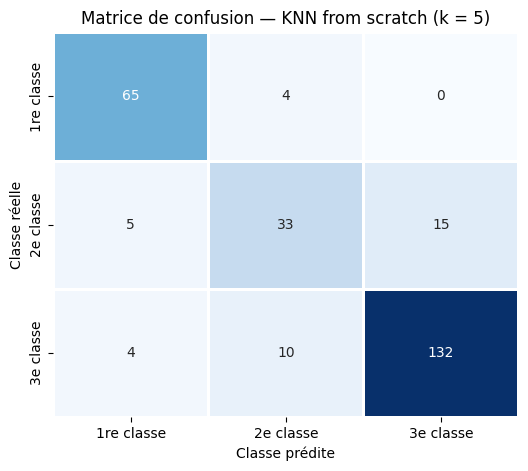

In [17]:
fig, ax = plt.subplots(figsize=(6, 5))
etiquettes = [NOMS[c] for c in knn.classes_]
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=2, linecolor="white",
            xticklabels=etiquettes, yticklabels=etiquettes, ax=ax)
ax.set_xlabel("Classe prédite")
ax.set_ylabel("Classe réelle")
ax.set_title(f"Matrice de confusion — KNN from scratch (k = {k_optimal})")
plt.show()

**Lecture de la matrice :**
- La **3ᵉ classe** est très bien reconnue (billets peu chers, majorité de la population).
- La **1ʳᵉ classe** est bien identifiée grâce au prix élevé et à la présence d'une cabine.
- La plupart des erreurs concernent la **2ᵉ classe**, confondue avec la 3ᵉ : leurs prix de billet
  se chevauchent (voir l'histogramme de la section 1). C'est la classe la plus difficile.

## 2.5 Validation : comparaison avec scikit-learn
Même pré-traitement et même k avec `SimpleImputer` + `StandardScaler` + `KNeighborsClassifier`.

In [18]:
modele_sk = creer_pipeline(k_optimal).fit(X_train, y_train)
y_pred_sk = modele_sk.predict(X_test)

print(f"Concordance des prédictions scratch / scikit-learn : {np.mean(y_pred == y_pred_sk):.2%}")
print(f"Accuracy from scratch : {accuracy_scratch:.4f}")
print(f"Accuracy scikit-learn : {np.mean(y_pred_sk == y_test):.4f}\n")
print("Rapport scikit-learn :")
print(classification_report(y_test, y_pred_sk, target_names=etiquettes, digits=4))

Concordance des prédictions scratch / scikit-learn : 100.00%
Accuracy from scratch : 0.8582
Accuracy scikit-learn : 0.8582

Rapport scikit-learn :
              precision    recall  f1-score   support

  1re classe     0.8784    0.9420    0.9091        69
   2e classe     0.7021    0.6226    0.6600        53
   3e classe     0.8980    0.9041    0.9010       146

    accuracy                         0.8582       268
   macro avg     0.8262    0.8229    0.8234       268
weighted avg     0.8542    0.8582    0.8554       268



## 2.6 Prédiction pour de nouveaux passagers

In [19]:
def predire_classe(fare, age, sibsp, parch, femme, cabine, survecu, modele=knn):
    x = [[np.log1p(fare), age, sibsp, parch, int(femme), int(cabine), int(survecu)]]
    x_std = pretraiter(x)
    classe = modele.predict(x_std)[0]
    proba = modele.predict_proba(x_std)[0]
    detail = ", ".join(f"{NOMS[c]} : {p:.0%}" for c, p in zip(modele.classes_, proba))
    print(f"Fare={fare:>6}, Age={str(age):>4}, femme={int(femme)}, cabine={int(cabine)}  ->  "
          f"{NOMS[classe]:<10} ({detail})")
    return classe


predire_classe(fare=150, age=45, sibsp=1, parch=0, femme=True, cabine=True, survecu=True)
predire_classe(fare=13, age=30, sibsp=0, parch=0, femme=False, cabine=False, survecu=False)
predire_classe(fare=7.9, age=22, sibsp=0, parch=0, femme=False, cabine=False, survecu=False)
predire_classe(fare=26, age=np.nan, sibsp=1, parch=1, femme=True, cabine=False, survecu=True)

Fare=   150, Age=  45, femme=1, cabine=1  ->  1re classe (1re classe : 100%, 2e classe : 0%, 3e classe : 0%)
Fare=    13, Age=  30, femme=0, cabine=0  ->  2e classe  (1re classe : 0%, 2e classe : 80%, 3e classe : 20%)
Fare=   7.9, Age=  22, femme=0, cabine=0  ->  3e classe  (1re classe : 0%, 2e classe : 0%, 3e classe : 100%)
Fare=    26, Age= nan, femme=1, cabine=0  ->  2e classe  (1re classe : 0%, 2e classe : 60%, 3e classe : 40%)


np.int64(2)

Le dernier passager n'a **pas d'âge renseigné** : l'imputeur from scratch le remplace
automatiquement par la médiane apprise sur l'entraînement.

---
# Conclusion

### Bilan
| | Dataset cancer (Q1-Q2) | Dataset Titanic (Q3) |
|---|---|---|
| Nombre de classes | 2 | **3** (`Pclass`) |
| Variables | 2 gènes, propres | 7 variables, avec valeurs manquantes et texte |
| Séparation des données | aléatoire stratifiée | **par groupe de billet** (évite la fuite familiale) |
| k optimal (CV 10 plis) | 21 | **5** |
| Accuracy test | 94,0 % | **85,8 %** (F1 macro 82,3 %) |
| Concordance avec scikit-learn | 100 % | **100 %** |

### Ce qu'il a fallu adapter pour le multi-classes
1. **Vote majoritaire générique** (`Counter`) qui fonctionne quel que soit le nombre de classes.
2. **Règle de départage** par le voisin le plus proche : avec 3 classes, un k impair ne suffit plus
   à éviter les égalités.
3. **Métriques par classe** + moyennes **macro** et **pondérée**, car l'accuracy seule masque les
   difficultés sur la classe minoritaire (2ᵉ classe).
4. **Pré-traitement from scratch** (imputation de la médiane, standardisation) appris sur
   l'entraînement uniquement.

### Limites
- La 2ᵉ classe reste la plus difficile (rappel ≈ 62 %, contre ≈ 94 % pour la 1ʳᵉ et ≈ 90 % pour la 3ᵉ) :
  son prix de billet chevauche celui de la 3ᵉ classe.
- Le jeu de test est petit (268 passagers) : quelques points d'accuracy de différence ne sont pas significatifs.
- KNN reste sensible au choix des variables : chaque variable ajoutée pèse autant dans la distance,
  même si elle est peu utile (ex. `Embarked`). Une sélection ou une pondération des variables pourrait encore améliorer le modèle.